# Pixel → Schachbrett-Koordinaten (Homographie)

YOLO liefert die Position eines Objekts in **Pixeln**. Der Roboter braucht aber eine Position **auf dem Brett**.
Dieses Notebook zeigt Schritt für Schritt, wie `calibrate_board.py` diese Umrechnung baut:

1. Innere Ecken des Schachbretts im Foto finden
2. Ihre Reihenfolge vereinheitlichen
3. Jeder Ecke ihre Brett-Koordinate (in Feldern) zuordnen
4. Daraus die Homographie berechnen
5. Prüfen: Raster zurück ins Bild zeichnen + Vogelperspektive
6. Mit YOLO kombinieren

Bildgröße (Höhe, Breite): (1600, 1200)


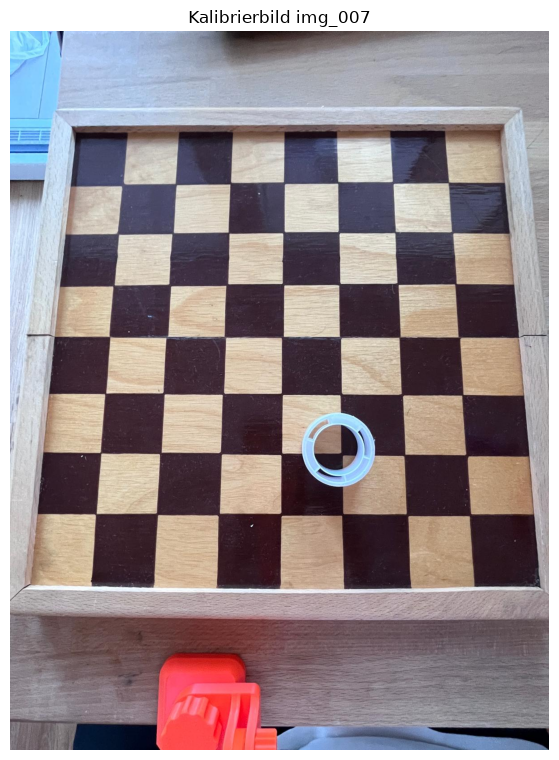

In [1]:
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np

# Projektordner so101-vision finden (egal ob das Notebook aus notebooks/ oder so101-vision/ läuft)
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

def show(img_bgr, title="", size=7):
    plt.figure(figsize=(size, size * img_bgr.shape[0] / img_bgr.shape[1]))
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title); plt.axis("off"); plt.show()

image = cv2.imread(str(ROOT / "data" / "raw" / "img_007.jpg"))
print("Bildgröße (Höhe, Breite):", image.shape[:2])
show(image, "Kalibrierbild img_007")

## 1. Innere Ecken finden

Ein Schachbrett hat 8×8 Felder, aber nur **7×7 innere Kreuzungen** (zwischen 8 Feldern liegen 7 Grenzen).
Genau diese sucht `findChessboardCornersSB`. Die Ecken am Holzrahmen sind zu unzuverlässig.

Gefunden: True | Anzahl Ecken: 49
Erste 3 Ecken in Pixeln:
 [[      251.1       342.5]
 [      369.5       340.9]
 [      491.1       338.8]]


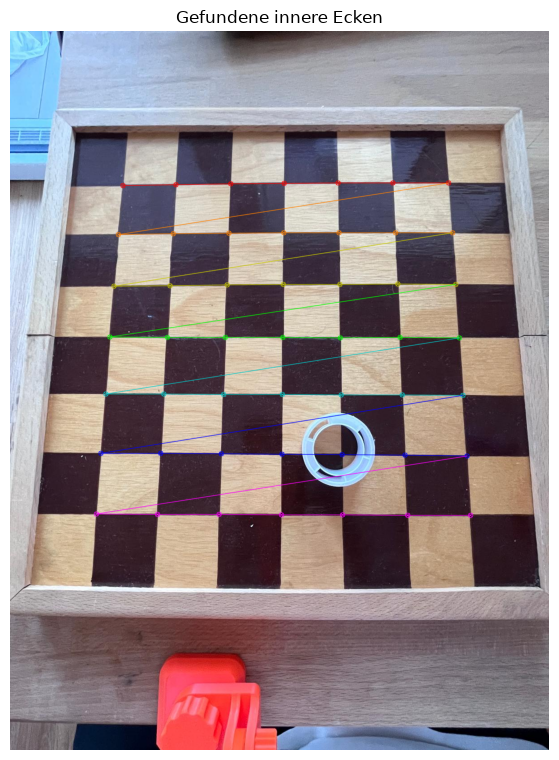

In [15]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
found, corners = cv2.findChessboardCornersSB(
    gray, (7, 7), flags=cv2.CALIB_CB_EXHAUSTIVE | cv2.CALIB_CB_ACCURACY)
print("Gefunden:", found, "| Anzahl Ecken:", len(corners))
print("Erste 3 Ecken in Pixeln:\n", corners[:3].reshape(-1, 2).round(1))

vis = image.copy()
cv2.drawChessboardCorners(vis, (7, 7), corners, found)
show(vis, "Gefundene innere Ecken")

## 2. Reihenfolge vereinheitlichen

OpenCV liefert die 49 Ecken als Liste, aber **in welcher Reihenfolge** (oben links oder unten rechts zuerst?)
hängt vom Bild ab. Wir sortieren sie in ein 7×7-Gitter: Zeile 0 = oben im Bild, Spalte 0 = links.
Die Zahlen zeigen den Index in der Original-Liste von OpenCV.

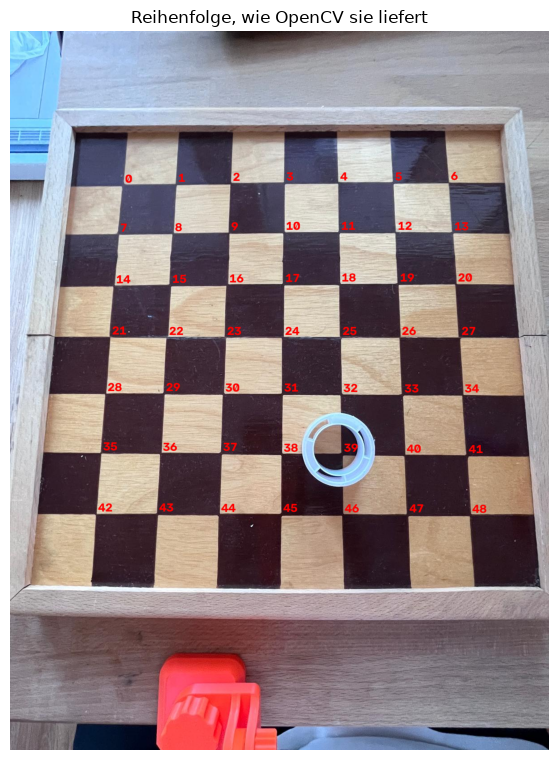

Gitterform: (7, 7, 2)
oben links : [251. 343.]   oben rechts: [976. 337.]
unten links: [ 192. 1074.]   unten rechts: [1025. 1077.]


In [3]:
vis = image.copy()
for i, (x, y) in enumerate(corners.reshape(-1, 2)):
    cv2.putText(vis, str(i), (int(x) + 5, int(y) - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 0, 255), 2)
show(vis, "Reihenfolge, wie OpenCV sie liefert")

from calibrate_board import find_inner_corners
grid = find_inner_corners(image)          # Form (7, 7, 2): grid[zeile, spalte] = (x, y) in Pixeln
print("Gitterform:", grid.shape)
print("oben links :", grid[0, 0].round(0), "  oben rechts:", grid[0, -1].round(0))
print("unten links:", grid[-1, 0].round(0), "  unten rechts:", grid[-1, -1].round(0))

## 3. Brett-Koordinaten zuordnen

Jetzt bekommt jede Ecke ihre Position **auf dem Brett**. Das geht ohne Maßband, weil alle Felder gleich groß sind:

- Ursprung (0, 0) = äußere Ecke unten links (Roboterseite)
- X nach rechts, Y vom Roboter weg, Einheit = 1 Feld
- die innere Ecke unten links liegt also bei (1, 1), die oben rechts bei (7, 7)

In [4]:
from calibrate_board import board_points
brd = board_points()                        # gleiche Form (7, 7, 2) wie grid

print("Pixel (x, y)        ->  Brett (X, Y) in Feldern")
for r, c in [(6, 0), (6, 1), (5, 0), (0, 6)]:
    print(f"{str(grid[r, c].round(0)):<20} ->  {brd[r, c]}")

Pixel (x, y)        ->  Brett (X, Y) in Feldern
[ 192. 1074.]        ->  [1. 1.]
[ 328. 1075.]        ->  [2. 1.]
[202. 939.]          ->  [1. 2.]
[976. 337.]          ->  [7. 7.]


## 4. Homographie berechnen

Wir haben jetzt 49 Paare *(Pixel ↔ Brett)*. Eine **Homographie** ist eine 3×3-Matrix `H`, die eine Ebene
auf eine andere abbildet und dabei auch die Perspektive ausgleicht (oben im Bild sind die Felder kleiner,
weil sie weiter weg sind). `findHomography` sucht das `H`, das alle 49 Paare am besten trifft.

Umrechnung eines Punkts: `[X', Y', w] = H · [x, y, 1]`, danach `X = X'/w`, `Y = Y'/w`. Die Division durch `w`
ist der Teil, der die Perspektive macht.

In [5]:
img_pts = grid.reshape(-1, 2)
brd_pts = brd.reshape(-1, 2)
H, _ = cv2.findHomography(img_pts, brd_pts)
np.set_printoptions(suppress=True, precision=5)
print("H =\n", H)

# Wie gut passt H? Brett-Punkte zurück ins Bild rechnen und mit den gefundenen Ecken vergleichen
back = cv2.perspectiveTransform(brd_pts.reshape(-1, 1, 2), np.linalg.inv(H)).reshape(-1, 2)
err = np.linalg.norm(back - img_pts, axis=1)
print(f"Reprojektionsfehler: Mittel {err.mean():.2f} px, Maximum {err.max():.2f} px")

# Von Hand nachgerechnet für einen Punkt:
x, y = img_pts[0]
Xp, Yp, w = H @ [x, y, 1]
print(f"Pixel ({x:.0f}, {y:.0f}) -> Brett ({Xp / w:.3f}, {Yp / w:.3f})   erwartet {brd_pts[0]}")

H =
 [[ 0.00911  0.00095 -1.52102]
 [ 0.0001  -0.00865 10.50144]
 [ 0.00003  0.00022  1.     ]]
Reprojektionsfehler: Mittel 1.51 px, Maximum 3.60 px
Pixel (251, 343) -> Brett (1.010, 6.997)   erwartet [1. 7.]


## 5. Prüfen

**a) Raster zurück ins Bild:** Wir zeichnen das ideale 8×8-Raster (Brett-Koordinaten 0…8) mit `H⁻¹` ins Foto.
Liegt es auf den Feldern, stimmt die Umrechnung, auch am Rand, wo gar keine Ecken gemessen wurden.

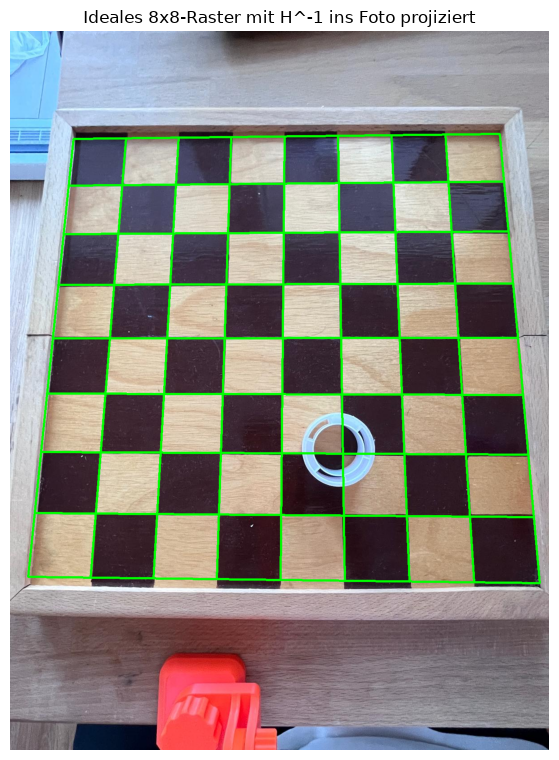

In [6]:
H_inv = np.linalg.inv(H)
def to_px(pts):
    return cv2.perspectiveTransform(np.array(pts, float).reshape(-1, 1, 2), H_inv).reshape(-1, 2).astype(int)

vis = image.copy()
for i in range(9):
    for a, b in (((i, 0), (i, 8)), ((0, i), (8, i))):
        p, q = to_px([a, b])
        cv2.line(vis, tuple(p), tuple(q), (0, 255, 0), 3)
show(vis, "Ideales 8x8-Raster mit H^-1 ins Foto projiziert")

**b) Vogelperspektive:** Mit `warpPerspective` kann man das ganze Foto in Brett-Koordinaten umrechnen.
So sieht das Bild aus, als hinge die Kamera genau senkrecht über dem Brett: alle Felder gleich groß und quadratisch.

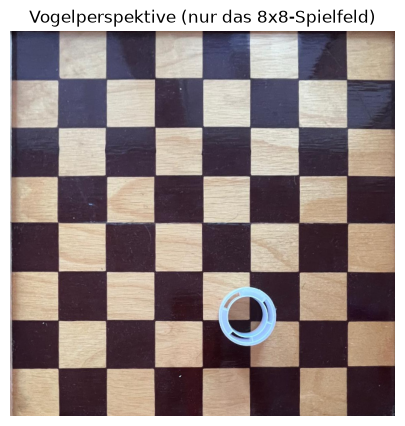

In [7]:
px_per_square = 80
S = np.diag([px_per_square, -px_per_square, 1.0])   # Felder -> Pixel im Zielbild, Y nach oben drehen
S[1, 2] = 8 * px_per_square                          # Ursprung nach unten links
top_down = cv2.warpPerspective(image, S @ H, (8 * px_per_square, 8 * px_per_square))
show(top_down, "Vogelperspektive (nur das 8x8-Spielfeld)", size=5)

## 6. Mit YOLO kombinieren

Das trainierte Modell findet die Objekte, `H` rechnet ihre Mittelpunkte auf das Brett um.
Genau das macht `predict.py` (mit der in `configs/board_calibration.json` gespeicherten Matrix).

marker   Pixel (717, 655)  ->  Brett (4.85, 4.23) Felder


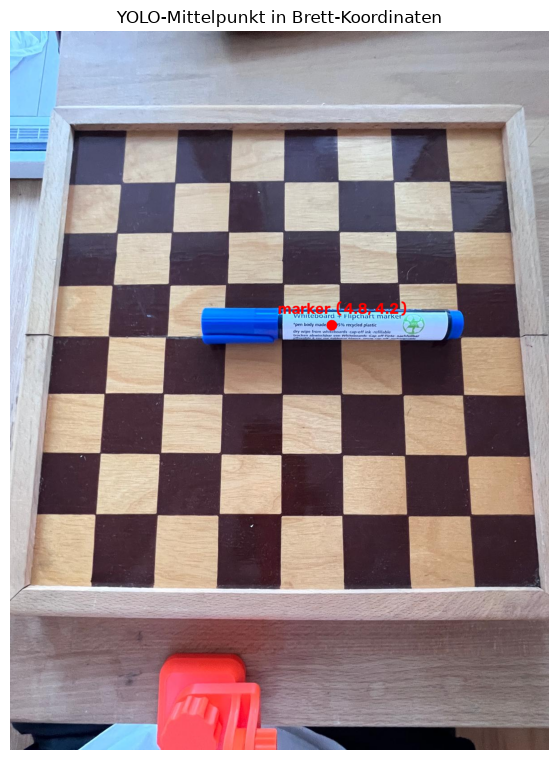

In [8]:
from ultralytics import YOLO

model = YOLO(ROOT / "runs" / "yolo26n_4cls_fixed" / "weights" / "best.pt")
test_img = cv2.imread(str(ROOT / "data" / "raw" / "img_029.jpg"))
result = model.predict(test_img, conf=0.5, verbose=False)[0]

vis = test_img.copy()
for box in result.boxes:
    cx, cy, _, _ = box.xywh[0].tolist()
    X, Y = cv2.perspectiveTransform(np.array([[[cx, cy]]]), H)[0, 0]
    name = model.names[int(box.cls)]
    print(f"{name:<8} Pixel ({cx:.0f}, {cy:.0f})  ->  Brett ({X:.2f}, {Y:.2f}) Felder")
    cv2.circle(vis, (int(cx), int(cy)), 12, (0, 0, 255), -1)
    cv2.putText(vis, f"{name} ({X:.1f}, {Y:.1f})", (int(cx) - 120, int(cy) - 25),
                cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 255), 3)
show(vis, "YOLO-Mittelpunkt in Brett-Koordinaten")

## Von Feldern zu Millimetern

Für den Roboter fehlt nur noch ein Faktor: **Position in mm = Position in Feldern × Feldgröße in mm**.
Feld nachmessen und eintragen:

In [9]:
square_mm = None   # z.B. 45.0, nachgemessen
if square_mm:
    print(f"Marker bei ({X * square_mm:.0f}, {Y * square_mm:.0f}) mm vom Brett-Ursprung")
else:
    print("square_mm eintragen, dann wird hier in mm umgerechnet.")

square_mm eintragen, dann wird hier in mm umgerechnet.
